<a href="https://colab.research.google.com/github/carbonconundrum158/Text-message-sentiment-analysis/blob/main/sentimentanalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Text Message Sentiment Analysis with Emotion-Labeled Dataset

**Dataset:** [Emotions Dataset on Kaggle](https://www.kaggle.com/datasets/nelgiriyewithana/emotions)

**Features:**
- `text`: A string feature representing the content of the Twitter message.
- `label`: A classification label indicating the primary emotion, with values ranging from 0 to 5.

---

## Project Overview

We will use a dataset of **416,809 English Twitter messages**, each labeled with one of six emotions:

- Sadness
- Joy
- Love
- Anger
- Fear
- Surprise

Our goal is to determine which combination of **feature representation** and **classifier** best detects emotion in text. The dataset is **class-imbalanced** and contains **conflicting labels** between related emotions (e.g., joy vs. love, or fear vs. surprise), making it a useful setting for comparing how well different approaches handle ambiguous messages.

---

## Project Goal

The main goal is to identify the **best-performing combination** of feature representation and classifier for emotion detection.

**Feature Representations (5):**
1. Bag of Words
2. TF-IDF
3. Word2Vec
4. GloVe
5. Transformer-based embeddings (e.g., BERT / DistilBERT)

**Classifiers (4):**
1. Naive Bayes
2. Logistic Regression
3. SVM
4. Fine-tuned Transformer (e.g., DistilBERT)

**Evaluation Metrics:**
- Accuracy
- Macro-F1
- Per-class performance

> **Note:** Naive Bayes will only be paired with **Bag of Words** and **TF-IDF**, since it requires non-negative features and is not suited to dense word embeddings. The **fine-tuned Transformer** classifier will be evaluated as its own end-to-end pipeline (not paired with the other feature representations), since transformer models learn their own contextual embeddings internally rather than consuming precomputed features.

The best-performing model will then be used to analyze new text messages, providing a **predicted emotion** and a **probability distribution** across all six emotions.


DATA PRE PROCESSING


The Shape Of Data Is : (416809, 3)


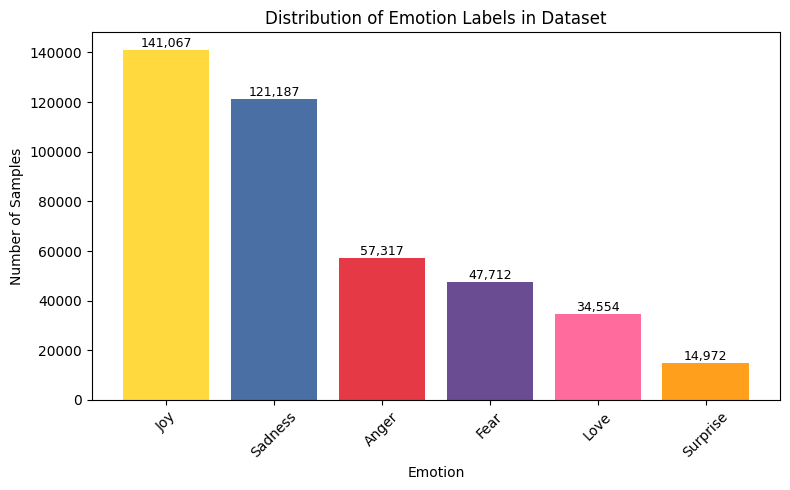


Label counts:
label
Joy         141067
Sadness     121187
Anger        57317
Fear         47712
Love         34554
Surprise     14972
Name: count, dtype: int64


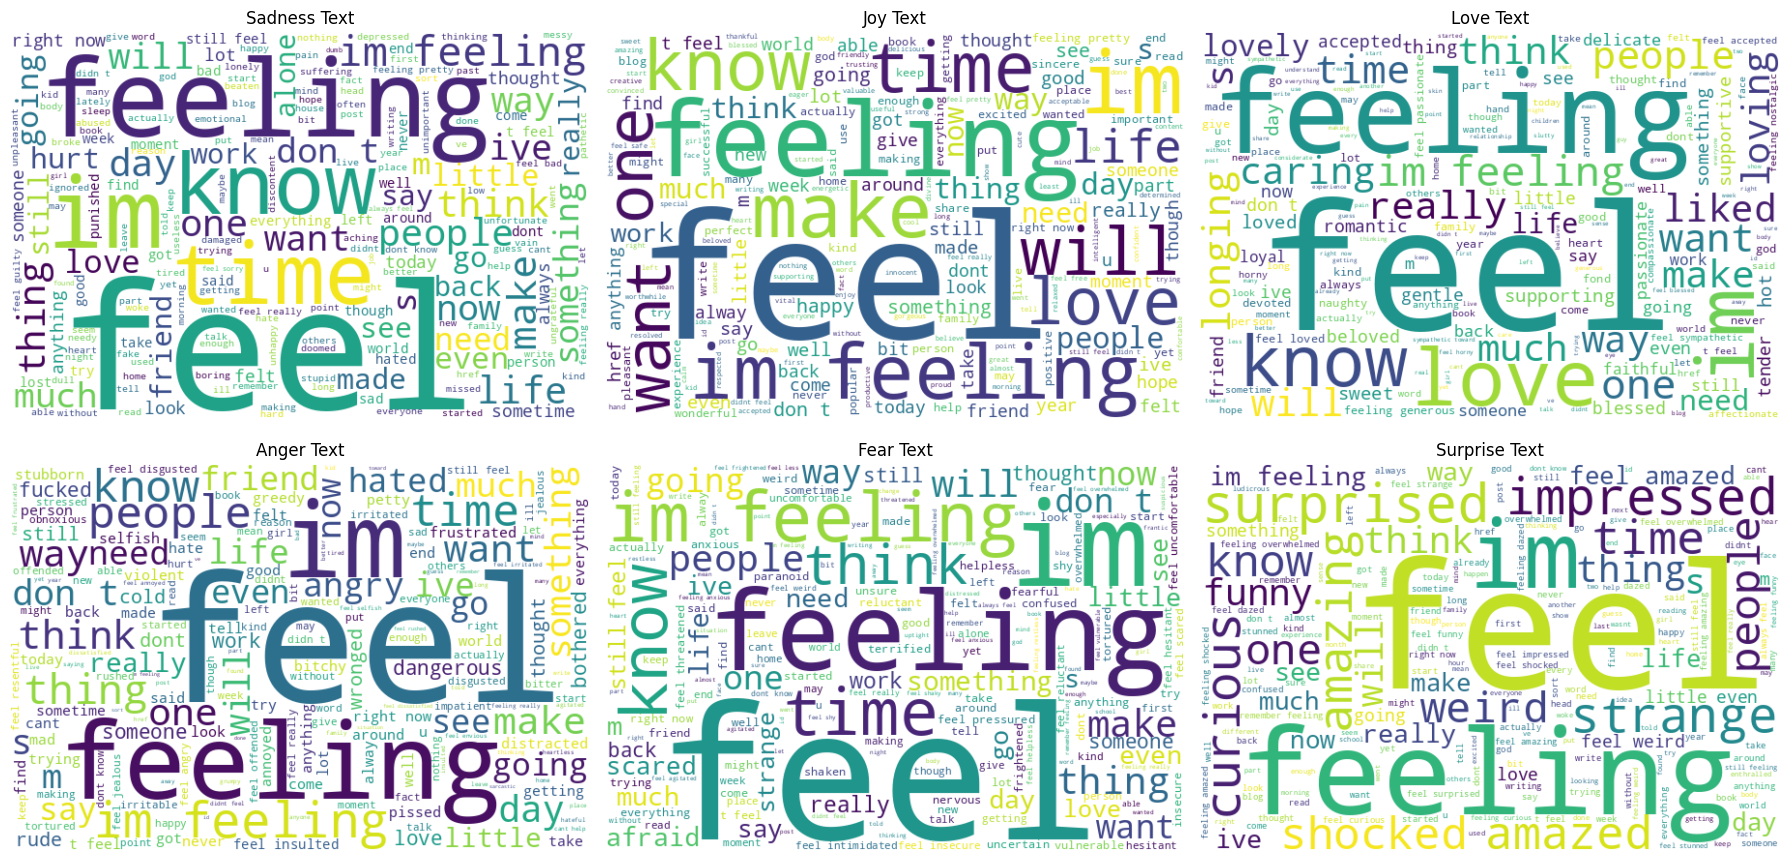

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

#Data Pre Processing
DATA_PATH = Path("text.csv")  #dataset must be named text.csv Column 0: text Column 1: label
df  = pd.read_csv(DATA_PATH)

print(f'The Shape Of Data Is : {df.shape}') #See Shape of DF

df.isnull().sum() #Checks for Null entries
df.duplicated().sum()#Checks for duplicates
df = df.drop(columns=['Unnamed: 0'])#Removes redundant column
df.head()




#Show Data Distribution
emotion_map = {0: 'Sadness', 1: 'Joy', 2: 'Love', 3: 'Anger', 4: 'Fear', 5: 'Surprise'}

emotion_colors = {
    0: '#4A6FA5',   # Sadness - blue
    1: '#FFD93D',   # Joy - yellow
    2: '#FF6B9D',   # Love - pink
    3: '#E63946',   # Anger - red
    4: '#6A4C93',   # Fear - purple
    5: '#FF9F1C',   # Surprise - orange
}

label_counts = df['label'].value_counts().sort_values(ascending=False)
colors = [emotion_colors[i] for i in label_counts.index]

plt.figure(figsize=(8, 5))
bars = plt.bar([emotion_map[i] for i in label_counts.index], label_counts.values, color=colors)

plt.xlabel('Emotion')
plt.ylabel('Number of Samples')
plt.title('Distribution of Emotion Labels in Dataset')
plt.xticks(rotation=45)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height, f'{height:,}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

print("\nLabel counts:")
print(label_counts.rename(index=emotion_map))

# Generate word clouds per emotion  (Found from https://www.kaggle.com/code/abdmental01/emotions-analysis-gru-94)
from wordcloud import WordCloud

def generate_wordcloud(label_value):
    text_combined = " ".join(df.loc[df['label'] == label_value, 'text'].astype(str))
    return WordCloud(width=600, height=400, background_color='white',
                      colormap='viridis').generate(text_combined)

sadness_wordcloud = generate_wordcloud(0)
joy_wordcloud = generate_wordcloud(1)
love_wordcloud = generate_wordcloud(2)
anger_wordcloud = generate_wordcloud(3)
fear_wordcloud = generate_wordcloud(4)
surprise_wordcloud = generate_wordcloud(5)

# Plot the word clouds
plt.figure(figsize=(18, 9))

plt.subplot(2, 3, 1)
plt.imshow(sadness_wordcloud, interpolation='bilinear')
plt.title('Sadness Text')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(joy_wordcloud, interpolation='bilinear')
plt.title('Joy Text')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(love_wordcloud, interpolation='bilinear')
plt.title('Love Text')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(anger_wordcloud, interpolation='bilinear')
plt.title('Anger Text')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(fear_wordcloud, interpolation='bilinear')
plt.title('Fear Text')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(surprise_wordcloud, interpolation='bilinear')
plt.title('Surprise Text')
plt.axis('off')

plt.tight_layout()
plt.show()


TF IDF: Linear Regression, Naive Bayes

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Split data: 80% train, 10% dev, 10% test
train_df, temp_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label'])
dev_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42, stratify=temp_df['label'])

print(f"Train size: {len(train_df)}, Dev size: {len(dev_df)}, Test size: {len(test_df)}")

# Fit TF-IDF only on training data to avoid data leakage
tfidf_vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
X_train_tfidf = tfidf_vectorizer.fit_transform(train_df['text'])
X_dev_tfidf = tfidf_vectorizer.transform(dev_df['text'])
X_test_tfidf = tfidf_vectorizer.transform(test_df['text'])

y_train = train_df['label']
y_dev = dev_df['label']
y_test = test_df['label']

print(f"TF-IDF matrix shape: {X_train_tfidf.shape}")

# ---- Naive Bayes ----
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

nb_dev_preds = nb_model.predict(X_dev_tfidf)
nb_dev_preds = nb_model.predict(X_dev_tfidf)
print("Naive Bayes (Dev Set):")
print(f"  Accuracy: {accuracy_score(y_dev, nb_dev_preds):.4f}")
print(f"  Macro-F1: {f1_score(y_dev, nb_dev_preds, average='macro'):.4f}")

# Per-class performance
print("\nNaive Bayes Classification Report (Dev):")
print(classification_report(y_dev, nb_dev_preds, target_names=list(emotion_map.values())))


# ---- Logistic Regression ----
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

lr_dev_preds = lr_model.predict(X_dev_tfidf)
print("\nLogistic Regression (Dev Set):")
print(f"  Accuracy: {accuracy_score(y_dev, lr_dev_preds):.4f}")
print(f"  Macro-F1: {f1_score(y_dev, lr_dev_preds, average='macro'):.4f}")

# Per-class performance
print("\nLogistic Regression Classification Report (Dev):")
print(classification_report(y_dev, lr_dev_preds, target_names=list(emotion_map.values())))

# ---- Linear SVM ----
svm_model = LinearSVC(max_iter=2000)
svm_model.fit(X_train_tfidf, y_train)

svm_dev_preds = svm_model.predict(X_dev_tfidf)
print("\nLinear SVM (Dev Set):")
print(f"  Accuracy: {accuracy_score(y_dev, svm_dev_preds):.4f}")
print(f"  Macro-F1: {f1_score(y_dev, svm_dev_preds, average='macro'):.4f}")

# Per-class performance
print("\nLinear SVM Classification Report (Dev):")
print(classification_report(y_dev, svm_dev_preds, target_names=list(emotion_map.values())))

Train size: 333447, Dev size: 41681, Test size: 41681
TF-IDF matrix shape: (333447, 10000)
Naive Bayes (Dev Set):
  Accuracy: 0.8445
  Macro-F1: 0.7644

Naive Bayes Classification Report (Dev):
              precision    recall  f1-score   support

     Sadness       0.86      0.94      0.90     12119
         Joy       0.79      0.97      0.87     14107
        Love       0.90      0.48      0.62      3455
       Anger       0.92      0.79      0.85      5732
        Fear       0.89      0.74      0.81      4771
    Surprise       0.89      0.39      0.54      1497

    accuracy                           0.84     41681
   macro avg       0.88      0.71      0.76     41681
weighted avg       0.85      0.84      0.84     41681


Logistic Regression (Dev Set):
  Accuracy: 0.9012
  Macro-F1: 0.8560

Logistic Regression Classification Report (Dev):
              precision    recall  f1-score   support

     Sadness       0.94      0.95      0.94     12119
         Joy       0.91      0.94 

Message length statistics by emotion:


,count,mean,median,std
label,,,,
0,121187,18.49,16.0,11.01
1,141067,19.54,17.0,10.91
2,34554,20.82,19.0,11.15
3,57317,19.03,17.0,11.27
4,47712,18.96,17.0,11.08
5,14972,19.74,18.0,11.02


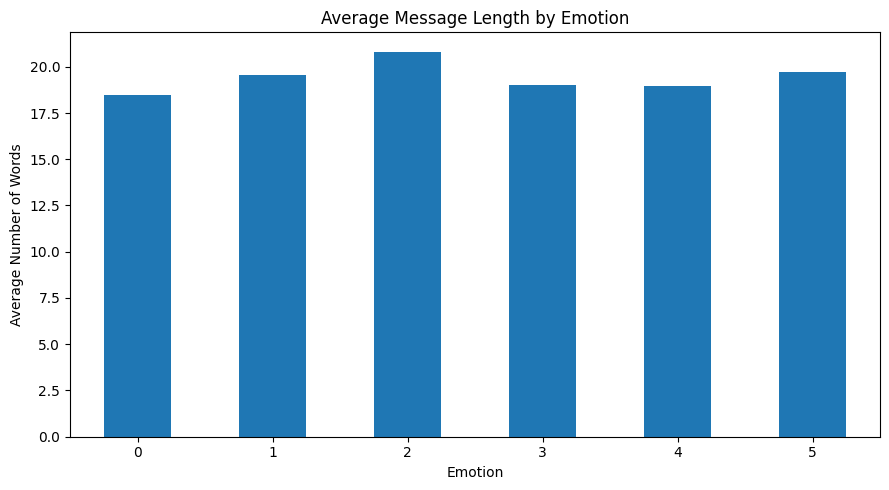

In [5]:

# ============================================
# Message Length Analysis
# ============================================

import pandas as pd
import matplotlib.pyplot as plt

# Work on a copy without modifying the original
length_df = df.copy()

# Calculate the number of words per message
length_df["word_count"] = (
    length_df["text"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

# Summary statistics by emotion
length_summary = (
    length_df.groupby("label")["word_count"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std"
    )
    .round(2)
)

print("Message length statistics by emotion:")
display(length_summary)

# Visualize average message length
length_summary["mean"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Message Length by Emotion")
plt.xlabel("Emotion")
plt.ylabel("Average Number of Words")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Chi-Square Vocabulary Analysis

### Objective

We investigate which unigrams (individual words) and bigrams (consecutive word pairs) are most strongly associated with each emotion category.

The χ² statistic is used to measure the association between vocabulary terms and emotion labels. We also compare term occurrence rates within the target class against the remaining classes to establish the direction of each association.

This analysis is exploratory and will not be used to select model features from the full dataset. Feature selection for predictive modeling must be performed on the training set only.

In [6]:
# Chi-Square Vocabulary Analysis
# Unigrams and Bigrams

import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import chi2

emotion_names = {
    0: "Sadness",
    1: "Joy",
    2: "Love",
    3: "Anger",
    4: "Fear",
    5: "Surprise"
}

# Use the original dataset for exploratory analysis.
# Map string labels to numeric IDs if necessary.
label_to_id = {
    name: idx for idx, name in emotion_names.items()
}

analysis_df = df[["text", "label"]].copy()
analysis_df["text"] = (
    analysis_df["text"].fillna("").astype(str)
)

if not pd.api.types.is_numeric_dtype(
    analysis_df["label"]
):
    analysis_df["label"] = (
        analysis_df["label"].map(label_to_id)
    )

assert analysis_df["label"].notna().all(), (
    "Unknown or missing emotion labels."
)

def analyze_vocabulary(ngram_range, top_n=15):
    vectorizer = CountVectorizer(
        binary=True,
        ngram_range=ngram_range,
        min_df=5,
        max_features=20000
    )

    X = vectorizer.fit_transform(
        analysis_df["text"]
    )

    terms = vectorizer.get_feature_names_out()
    results = {}

    for emotion_id, emotion in emotion_names.items():
        target = (
            analysis_df["label"].to_numpy()
            == emotion_id
        )

        scores, p_values = chi2(
            X,
            target.astype(int)
        )

        # Document occurrence rates, not term counts
        target_rates = (
            np.asarray(X[target].mean(axis=0))
            .ravel()
        )

        other_rates = (
            np.asarray(X[~target].mean(axis=0))
            .ravel()
        )

        table = pd.DataFrame({
            "term": terms,
            "chi2": scores,
            "p_value": p_values,
            "target_rate": target_rates,
            "other_rate": other_rates
        })

        # Keep terms more common in target class
        table = table[
            table["target_rate"]
            > table["other_rate"]
        ]

        table = table.sort_values(
            "chi2",
            ascending=False
        ).head(top_n)

        results[emotion] = table.reset_index(
            drop=True
        )

    return results

# Analyze individual words
unigram_results = analyze_vocabulary((1, 1))

# Analyze consecutive word pairs
bigram_results = analyze_vocabulary((2, 2))

print("Chi-square vocabulary analysis completed.")


Chi-square vocabulary analysis completed.


In [7]:
# Display Compact Vocabulary Results

def summarize_terms(results, top_n=10):
    return pd.DataFrame({
        emotion: (
            table["term"]
            .head(top_n)
            .reset_index(drop=True)
        )
        for emotion, table in results.items()
    })

print("TOP UNIGRAMS BY EMOTION")
display(summarize_terms(unigram_results))

print("\nTOP BIGRAMS BY EMOTION")
display(summarize_terms(bigram_results))


TOP UNIGRAMS BY EMOTION


,Sadness,Joy,Love,Anger,Fear,Surprise
0,worthless,more,sympathetic,annoyed,pressured,impressed
1,homesick,relaxed,tender,rude,apprehensive,amazed
2,isolated,confident,gentle,resentful,reluctant,shocked
3,dull,worthwhile,longing,irritated,hesitant,curious
4,aching,energetic,caring,dissatisfied,intimidated,surprised
5,useless,valued,horny,disgusted,shaky,funny
6,lethargic,comfortable,naughty,bitchy,unsure,dazed
7,shitty,privileged,romantic,wronged,insecure,stunned
8,groggy,valuable,nostalgic,greedy,uncertain,strange
9,burdened,acceptable,loving,selfish,paranoid,weird



TOP BIGRAMS BY EMOTION


,Sadness,Joy,Love,Anger,Fear,Surprise
0,sorry for,privileged to,fond of,fucked up,reluctant to,feel amazed
1,feel guilty,feel free,feel loved,feel insulted,feel pressured,impressed with
2,feel ashamed,feel safe,feel sympathetic,pissed off,feel threatened,dazed and
3,being punished,eager to,longing for,feel disgusted,pressured to,feel funny
4,feel terrible,feel more,loyal to,feel offended,feel uncomfortable,feel shocked
5,feel bad,feel comfortable,passionate about,feel jealous,apprehensive about,feel impressed
6,feel sorry,free to,feeling nostalgic,dissatisfied with,feel reluctant,amazed at
7,feel embarrassed,feel valued,the gentle,envious of,feel intimidated,feel curious
8,feel awful,feel privileged,devoted to,feel angry,hesitant to,curious about
9,in vain,pleased with,sympathetic towards,feel resentful,intimidated by,feel surprised


### Vocabulary Analysis: Results and Discussion

The chi-square analysis identified distinct vocabulary patterns across the six emotion categories.

For unigrams, sadness was strongly associated with terms such as *worthless*, *homesick*, and *isolated*, while joy was associated with *relaxed*, *confident*, and *energetic*. Love was characterized by terms such as *sympathetic*, *tender*, and *romantic*. Anger was associated with *annoyed*, *rude*, and *irritated*, whereas fear showed associations with *apprehensive*, *intimidated*, and *paranoid*. Surprise was associated with *impressed*, *amazed*, and *shocked*.

The bigram analysis revealed frequent emotion-related expressions, including *feel guilty* (sadness), *feel loved* (love), *feel threatened* (fear), and *feel shocked* (surprise). These patterns indicate that short phrases can provide additional context to individual emotion-related words.

These findings motivate evaluating both unigram and unigram-plus-bigram feature representations in subsequent classification experiments.

**Methodological note:** Chi-square measures statistical association, not predictive importance or causal influence. The results are exploratory and were calculated using the complete dataset; they will not be used directly for training-time feature selection.

## Conflicting Emotion Label Analysis

### Objective

We investigate whether identical text messages appear in the dataset with different emotion labels.

Such conflicts introduce ambiguity into single-label classification because a deterministic classifier cannot assign two different predictions to an identical input.

The analysis identifies the number of conflicting texts, the number of affected records, and the most frequently occurring pairs of conflicting emotions.

The results will inform the construction of conflict-inclusive and consistent-label dataset variants.

In [8]:
# Conflicting Emotion Label Analysis

import pandas as pd
from itertools import combinations
from collections import Counter

conflict_df = analysis_df[["text", "label"]].copy()

# Normalize whitespace for exact-text comparison
conflict_df["text_key"] = (
    conflict_df["text"]
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# Number of different labels per unique text
label_counts = (
    conflict_df.groupby("text_key")["label"]
    .nunique()
)

conflicting_texts = set(
    label_counts[label_counts > 1].index
)

conflicting_rows = conflict_df[
    conflict_df["text_key"].isin(conflicting_texts)
]

print("Total dataset records:", len(conflict_df))
print("Unique normalized texts:",
      conflict_df["text_key"].nunique())
print("Texts with conflicting labels:",
      len(conflicting_texts))
print("Records involved in conflicts:",
      len(conflicting_rows))
print("Percentage of records involved:",
      f"{100 * len(conflicting_rows) / len(conflict_df):.2f}%")

# Count unique texts associated with each emotion pair
labels_per_text = (
    conflicting_rows.groupby("text_key")["label"]
    .agg(lambda values: sorted(set(values)))
)

pair_counts = Counter()

for labels in labels_per_text:
    for label_a, label_b in combinations(labels, 2):
        pair = (
            emotion_names[label_a],
            emotion_names[label_b]
        )
        pair_counts[pair] += 1

pair_summary = pd.DataFrame([
    {
        "Emotion Pair": f"{a} – {b}",
        "Conflicting Texts": count
    }
    for (a, b), count in pair_counts.items()
]).sort_values(
    "Conflicting Texts",
    ascending=False
).reset_index(drop=True)

print("\nMost frequent conflicting emotion pairs:")
display(pair_summary.head(10))


Total dataset records: 416809
Unique normalized texts: 393822
Texts with conflicting labels: 22295
Records involved in conflicts: 44650
Percentage of records involved: 10.71%

Most frequent conflicting emotion pairs:


,Emotion Pair,Conflicting Texts
0,Joy – Love,10119
1,Fear – Surprise,3729
2,Sadness – Anger,2695
3,Anger – Fear,2214
4,Sadness – Fear,2138
5,Joy – Surprise,1286
6,Sadness – Surprise,114
7,Joy – Anger,5
8,Joy – Fear,5
9,Sadness – Joy,3


### Conflicting-Label Analysis: Results and Discussion

The analysis identified **22,295 unique normalized texts** associated with multiple emotion labels, involving **44,650 records (10.71% of the original dataset)**.

The most frequent conflicting emotion pairs were Joy–Love (10,119 texts), Fear–Surprise (3,729), Sadness–Anger (2,695), Anger–Fear (2,214), and Sadness–Fear (2,138).

The concentration of conflicts among semantically related emotions suggests that some labels may be difficult to distinguish using text alone. However, these inconsistencies may also reflect annotation practices or dataset-construction noise; their causes cannot be established from the present analysis.

In a single-label classification task, identical messages associated with different labels create an inherent limitation for deterministic predictions. This motivates retaining both a conflict-inclusive dataset and a consistent-label dataset for subsequent experiments.

**Note:** The first two emotion-pair counts match the midterm report exactly. Three other reported pair counts differ slightly from the reproduced results and should be reconciled before the final report.

## Text Artifact Detection and Cleaning

### Objective

The dataset is examined for residual web-related artifacts, including URL fragments, HTML attributes, and other markup remnants.

The objective is to identify and remove nonlinguistic artifacts while preserving meaningful emotional content and retaining all original records.

Cleaning is performed on a separate text column so that the original messages remain available for comparison and reproducibility.

After cleaning, we will reassess duplicate text-label pairs and conflicting labels to determine how preprocessing affects the dataset.

In [9]:
# Text Artifact Detection

import pandas as pd
import re

# Preserve the original dataset
artifact_df = df[["text", "label"]].copy()
artifact_df["text"] = (
    artifact_df["text"].fillna("").astype(str)
)

# Detect different categories of artifacts
artifact_patterns = {
    "HTML-like attributes": (
        r"\b(?:a\s+href|a\s+class|img\s+src|"
        r"var\s+fb\s+comment)\b"
    ),
    "HTTP or WWW tokens": r"\b(?:http|https|www)\b",
    "HTML entities": r"&(?:amp|lt|gt|quot|nbsp);",
    "HTML tags": r"<[^>]+>",
    "Empty or whitespace-only": r"^\s*$"
}

artifact_masks = {}

for name, pattern in artifact_patterns.items():
    artifact_masks[name] = (
        artifact_df["text"].str.contains(
            pattern,
            regex=True,
            case=False,
            na=False
        )
    )

# Results by artifact category
artifact_summary = pd.DataFrame({
    "Artifact Type": list(artifact_masks.keys()),
    "Affected Records": [
        int(mask.sum())
        for mask in artifact_masks.values()
    ]
})

artifact_summary["Percentage"] = (
    100 * artifact_summary["Affected Records"]
    / len(artifact_df)
).round(2)

print("Artifact detection summary:")
display(artifact_summary)

# Calculate the union of all detected artifacts.
# A record is counted only once, even if it
# contains multiple artifact categories.
any_artifact = pd.concat(
    artifact_masks.values(),
    axis=1
).any(axis=1)

print(
    "\nUnique records containing at least "
    "one detected artifact:",
    int(any_artifact.sum())
)

print(
    "Percentage of dataset:",
    f"{100 * any_artifact.mean():.2f}%"
)

# Inspect sample messages
print("\nExamples of messages containing artifacts:")
display(
    artifact_df.loc[
        any_artifact, ["text", "label"]
    ].head(15)
)


Artifact detection summary:


,Artifact Type,Affected Records,Percentage
0,HTML-like attributes,4925,1.18
1,HTTP or WWW tokens,5660,1.36
2,HTML entities,0,0.00
3,HTML tags,0,0.00
4,Empty or whitespace-only,0,0.00



Unique records containing at least one detected artifact: 5857
Percentage of dataset: 1.41%

Examples of messages containing artifacts:


,text,label
36,i admit some of my inspiration to go this dire...,0
180,i feel paranoid a href http cyncake,4
296,i just feel like i want to change it again a h...,1
345,i feel resistance and in this i forgive myself...,2
348,i feel so cold a href http hoyhenkeijukainen,3
353,i feel bad for her but i a href http lolhunt,0
385,i feel inspired to share a class post count li...,1
601,i feel needy posted by a href http jumbleupon,0
650,i have pictures everywhereee and i even manage...,1
708,i really have to double time with all my other...,1


In [10]:
# Inspect Artifact Patterns Before Cleaning

# Messages containing HTTP/WWW but no
# detected HTML-like attribute
http_only = (
    artifact_masks["HTTP or WWW tokens"]
    & ~artifact_masks["HTML-like attributes"]
)

# Messages containing HTML-like attributes
# but no detected HTTP/WWW token
html_only = (
    artifact_masks["HTML-like attributes"]
    & ~artifact_masks["HTTP or WWW tokens"]
)

# Messages containing both
both_types = (
    artifact_masks["HTML-like attributes"]
    & artifact_masks["HTTP or WWW tokens"]
)

print("HTTP/WWW only:", int(http_only.sum()))
print("HTML-like attributes only:", int(html_only.sum()))
print("Both categories:", int(both_types.sum()))

print("\nExamples: HTTP/WWW only")
for text in artifact_df.loc[
    http_only, "text"
].head(10):
    print("-", text)

print("\nExamples: HTML-like attributes only")
for text in artifact_df.loc[
    html_only, "text"
].head(10):
    print("-", text)

print("\nExamples: Both categories")
for text in artifact_df.loc[
    both_types, "text"
].head(10):
    print("-", text)


HTTP/WWW only: 932
HTML-like attributes only: 197
Both categories: 4728

Examples: HTTP/WWW only
- i feel so inadequate img alt src http www
- i havnt got too many videos on my channel but i want to get there soon making some when i have free time and am feeling inspired to show myself off p iframe width height src http www
- i feeling dangerous at wimbledon height src http www
- i feel it lyrics tekst pjesme lyrics free download mp link rel stylesheet href http tekstovilyrics
- i feel amazing form action http www
- i feel pretty oh so pretty st url http thumbpress
- i feel delicious pagetype index url http ifeeldelicious
- i feel useful says genevieve nnaji on amstel malta endorsement deal url http africamusiclaw
- i feel irritated with the spray script type text javascript src http pagead
- i feel rotten class buffer add button data count vertical data via wizzardsblog buffer script type text javascript src http static

Examples: HTML-like attributes only
- i left my house to teach a

In [11]:
 # Refined Web Artifact Detection

import re
import pandas as pd

# Match explicit markup and URL-related patterns.
# Avoid generic phrases such as "a class".
refined_patterns = {
    "Anchor fragments": (
        r"\ba\s+href\b|"
        r"\ba\s+class\s+post\s+count\s+link\b"
    ),
    "Image fragments": r"\bimg\s+(?:alt\s+)?src\b",
    "Iframe fragments": r"\biframe\b",
    "Script fragments": r"\bscript\s+type\b",
    "Form fragments": r"\bform\s+action\b",
    "URL references": (
        r"\b(?:https?|www)\b|"
        r"\burl\s+http\b"
    ),
    "Stylesheet links": r"\blink\s+rel\s+stylesheet\b"
}

refined_masks = {
    name: artifact_df["text"].str.contains(
        pattern,
        case=False,
        regex=True,
        na=False
    )
    for name, pattern in refined_patterns.items()
}

refined_summary = pd.DataFrame({
    "Artifact Type": list(refined_masks.keys()),
    "Affected Records": [
        int(mask.sum())
        for mask in refined_masks.values()
    ]
})

refined_summary["Percentage"] = (
    100 * refined_summary["Affected Records"]
    / len(artifact_df)
).round(2)

refined_any = pd.concat(
    refined_masks.values(),
    axis=1
).any(axis=1)

print("Refined artifact detection:")
display(refined_summary)

print(
    "\nUnique records flagged:",
    int(refined_any.sum())
)

print(
    "Percentage flagged:",
    f"{refined_any.mean() * 100:.2f}%"
)

print("\nAdditional examples:")
for text in artifact_df.loc[
    refined_any, "text"
].head(15):
    print("-", text)


Refined artifact detection:


,Artifact Type,Affected Records,Percentage
0,Anchor fragments,4132,0.99
1,Image fragments,536,0.13
2,Iframe fragments,44,0.01
3,Script fragments,39,0.01
4,Form fragments,6,0.00
5,URL references,5660,1.36
6,Stylesheet links,6,0.00



Unique records flagged: 5768
Percentage flagged: 1.38%

Additional examples:
- i admit some of my inspiration to go this direction is because i am feeling a little melancholy that i won t be making my a href http www
- i feel paranoid a href http cyncake
- i just feel like i want to change it again a href http sweet pleione
- i feel resistance and in this i forgive myself that i have accepted and allowed myself to not realize that i can stay awake when as i feel tired when i am resisting working on something and not give into the a href http eqafe
- i feel so cold a href http hoyhenkeijukainen
- i feel bad for her but i a href http lolhunt
- i feel inspired to share a class post count link href http atnelsonnest
- i feel needy posted by a href http jumbleupon
- i have pictures everywhereee and i even managed to find places to put my paper roses my piece of scenery from senior musical the thing that says hope and the painting i made at nats which isnt that great but putting it up made 

In [13]:
# Text Artifact Cleaning

import re
import pandas as pd

# Preserve the original text
cleaning_df = df[["text", "label"]].copy()
cleaning_df["text_original"] = (
    cleaning_df["text"].fillna("").astype(str)
)

def clean_web_artifacts(text):
    text = str(text)

    # Remove recognizable HTML and URL fragments
    # while preserving the surrounding text.
    patterns = [
        r"\ba\s+class\s+post\s+count\s+link\s+href\s+http(?:\s+\S+)?",
        r"\ba\s+href\s+http(?:\s+\S+)?",
        r"\bimg\s+(?:alt\s+)?src\s+http(?:\s+\S+)?",
        r"\bp\s+iframe\s+width\s+height\s+src\s+http(?:\s+\S+)?",
        r"\biframe\s+width\s+height\s+src\s+http(?:\s+\S+)?",
        r"\bscript\s+type\s+text\s+javascript\s+src\s+http(?:\s+\S+)?",
        r"\bform\s+action\s+http(?:\s+\S+)?",
        r"\blink\s+rel\s+stylesheet\s+href\s+http(?:\s+\S+)?",
        r"\burl\s+http(?:\s+\S+)?"
    ]

    for pattern in patterns:
        text = re.sub(
            pattern,
            " ",
            text,
            flags=re.IGNORECASE
        )

    return re.sub(r"\s+", " ", text).strip()

# Apply cleaning
cleaning_df["text_cleaned"] = (
    cleaning_df["text_original"]
    .apply(clean_web_artifacts)
)

# Evaluate changes
modified_mask = (
    cleaning_df["text_original"]
    != cleaning_df["text_cleaned"]
)

empty_mask = cleaning_df["text_cleaned"].eq("")

print("Total records:", len(cleaning_df))
print("Modified records:", int(modified_mask.sum()))
print(
    "Percentage modified:",
    f"{100 * modified_mask.mean():.2f}%"
)
print("Empty cleaned messages:", int(empty_mask.sum()))

print(
    "Unique texts before cleaning:",
    cleaning_df["text_original"].nunique()
)
print(
    "Unique texts after cleaning:",
    cleaning_df["text_cleaned"].nunique()
)

# Display examples
print("\nExamples of cleaned messages:")
display(
    cleaning_df.loc[
        modified_mask,
        ["text_original", "text_cleaned"]
    ].head(15)
)


Total records: 416809
Modified records: 4655
Percentage modified: 1.12%
Empty cleaned messages: 0
Unique texts before cleaning: 393822
Unique texts after cleaning: 393031

Examples of cleaned messages:


,text_original,text_cleaned
36,i admit some of my inspiration to go this dire...,i admit some of my inspiration to go this dire...
180,i feel paranoid a href http cyncake,i feel paranoid
296,i just feel like i want to change it again a h...,i just feel like i want to change it again ple...
345,i feel resistance and in this i forgive myself...,i feel resistance and in this i forgive myself...
348,i feel so cold a href http hoyhenkeijukainen,i feel so cold
353,i feel bad for her but i a href http lolhunt,i feel bad for her but i
385,i feel inspired to share a class post count li...,i feel inspired to share
601,i feel needy posted by a href http jumbleupon,i feel needy posted by
650,i have pictures everywhereee and i even manage...,i have pictures everywhereee and i even manage...
708,i really have to double time with all my other...,i really have to double time with all my other...


### Text Cleaning Results

The cleaning procedure modified **4,655 of 416,809 messages (1.12%)**, removing recognizable web and HTML-related fragments while preserving the surrounding text.

No messages became empty after cleaning. The number of unique texts decreased from **393,822 to 393,031**, indicating that the transformation caused some previously distinct messages to become identical.

These results motivate reassessing duplicate text-label pairs and conflicting labels after cleaning.

The procedure is heuristic and may leave some malformed artifacts or remove adjacent tokens. Consequently, the cleaning results should be interpreted as a reproducible preprocessing approach rather than a guarantee that every artifact has been removed perfectly.

In [14]:
# Duplicate and Conflict Assessment
# After Text Cleaning

# Build a standardized text key
prepared_df = cleaning_df[
    ["text_cleaned", "label"]
].copy()

prepared_df = prepared_df.rename(
    columns={"text_cleaned": "text"}
)

prepared_df["text"] = (
    prepared_df["text"]
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# Count duplicate text-label pairs
duplicate_pairs = prepared_df.duplicated(
    subset=["text", "label"]
).sum()

# Count unique texts and repeated texts
text_frequency = prepared_df["text"].value_counts()

repeated_texts = (
    text_frequency > 1
).sum()

# Identify texts associated with multiple labels
label_diversity = (
    prepared_df.groupby("text")["label"]
    .nunique()
)

conflicting_keys = set(
    label_diversity[label_diversity > 1].index
)

conflicting_rows = prepared_df[
    prepared_df["text"].isin(conflicting_keys)
]

print("Total records:", len(prepared_df))
print("Unique cleaned texts:", prepared_df["text"].nunique())
print("Repeated text groups:", repeated_texts)
print("Duplicate text-label rows:", duplicate_pairs)
print("Conflicting text groups:", len(conflicting_keys))
print("Rows involved in conflicts:", len(conflicting_rows))


Total records: 416809
Unique cleaned texts: 393031
Repeated text groups: 23218
Duplicate text-label rows: 1526
Conflicting text groups: 22246
Rows involved in conflicts: 44650


In [15]:
# Construct Dataset Variants

# Variant B: Conflict-inclusive dataset
# Remove only redundant text-label pairs.
variant_b = (
    prepared_df
    .drop_duplicates(subset=["text", "label"])
    .reset_index(drop=True)
)

# Variant A: Consistent-label dataset
# Exclude every text associated with
# multiple distinct emotion labels.
label_diversity = (
    variant_b.groupby("text")["label"]
    .nunique()
)

conflicting_keys = set(
    label_diversity[label_diversity > 1].index
)

variant_a = (
    variant_b[
        ~variant_b["text"].isin(conflicting_keys)
    ]
    .drop_duplicates(subset=["text"])
    .reset_index(drop=True)
)

# Validate the variants
assert not variant_b.duplicated(
    subset=["text", "label"]
).any()

assert not variant_a.duplicated(
    subset=["text"]
).any()

assert (
    variant_a.groupby("text")["label"]
    .nunique().max() == 1
)

print("Dataset construction completed.")

print(
    "\nVariant A (consistent-label):",
    f"{len(variant_a):,} records"
)

print(
    "Variant B (conflict-inclusive):",
    f"{len(variant_b):,} records"
)

print(
    "\nUnique texts in Variant A:",
    f"{variant_a['text'].nunique():,}"
)

print(
    "Unique texts in Variant B:",
    f"{variant_b['text'].nunique():,}"
)

print("\nClass distribution — Variant A:")
display(variant_a["label"].value_counts())

print("\nClass distribution — Variant B:")
display(variant_b["label"].value_counts())


Dataset construction completed.

Variant A (consistent-label): 370,785 records
Variant B (conflict-inclusive): 415,283 records

Unique texts in Variant A: 370,785
Unique texts in Variant B: 393,031

Class distribution — Variant A:


,count
label,
1,129037
0,115798
3,52259
4,39546
2,24331
5,9814



Class distribution — Variant B:


,count
label,
1,140435
0,120727
3,57150
4,47605
2,34435
5,14931


### Dataset Variant Construction Results

Two dataset variants were constructed following artifact cleaning and deduplication.

| Dataset | Records | Unique cleaned texts |
|---|---:|---:|
| Variant A — Consistent-label | 370,785 | 370,785 |
| Variant B — Conflict-inclusive | 415,283 | 393,031 |

**Variant A** excludes all messages associated with multiple emotion labels, ensuring that each unique text has exactly one label.

**Variant B** retains conflicting-label messages while removing redundant records containing identical text-label pairs.

The consistent-label variant reproduces the 370,785 records reported in the midterm report. The conflict-inclusive variant contains six additional records compared with the reported figure, reflecting a small difference in the number of duplicate pairs identified after cleaning.

Both variants preserve all six emotion categories but exhibit substantial class imbalance, with Joy and Sadness remaining the largest classes.

These datasets will be used to investigate the effect of conflicting labels on emotion classification performance.

## Leakage-Free Train/Validation/Test Splitting

### Objective

Both dataset variants are divided into training, validation, and test subsets using an approximately 80/10/10 allocation.

To prevent exact-text leakage, splitting is performed at the unique cleaned-text level rather than the individual-record level.

Identical messages, including those associated with conflicting labels, are assigned to the same subset.

A shared text-to-split mapping is used for both dataset variants, ensuring that messages present in both datasets receive consistent assignments.

Stratification is applied using a representative label per unique text group to approximately preserve emotion-class distributions. Because conflicting texts may have multiple labels, exact class-level stratification is not guaranteed for the conflict-inclusive variant.

In [16]:
# Leakage-Free Train/Validation/Test Splitting

from sklearn.model_selection import train_test_split
import pandas as pd

RANDOM_STATE = 42

# Create one record per unique cleaned text.
# Use the minimum label as a deterministic
# stratification proxy for conflicting texts.
text_groups = (
    variant_b.groupby("text")["label"]
    .min()
    .reset_index()
)

# 80% training and 20% remaining
train_groups, remaining_groups = train_test_split(
    text_groups,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=text_groups["label"]
)

# Divide remaining 20% into validation and test
val_groups, test_groups = train_test_split(
    remaining_groups,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=remaining_groups["label"]
)

# Create shared assignments for both variants
split_mapping = {}

for split_name, groups in [
    ("train", train_groups),
    ("validation", val_groups),
    ("test", test_groups)
]:
    split_mapping.update(
        dict.fromkeys(groups["text"], split_name)
    )

variant_a_split = variant_a.copy()
variant_b_split = variant_b.copy()

variant_a_split["split"] = (
    variant_a_split["text"].map(split_mapping)
)

variant_b_split["split"] = (
    variant_b_split["text"].map(split_mapping)
)

# Validate assignments and exact-text separation
for name, data in [
    ("Variant A — Consistent-label", variant_a_split),
    ("Variant B — Conflict-inclusive", variant_b_split)
]:
    assert data["split"].notna().all()

    subsets = {
        split: set(
            data.loc[data["split"] == split, "text"]
        )
        for split in ["train", "validation", "test"]
    }

    assert subsets["train"].isdisjoint(
        subsets["validation"]
    )
    assert subsets["train"].isdisjoint(
        subsets["test"]
    )
    assert subsets["validation"].isdisjoint(
        subsets["test"]
    )

    counts = (
        data["split"]
        .value_counts()
        .reindex(["train", "validation", "test"])
    )

    summary = pd.DataFrame({
        "Records": counts,
        "Percentage": (
            100 * counts / len(data)
        ).round(2)
    })

    print(f"\n{name}")
    display(summary)

# Explicitly verify that text assignments
# agree wherever the variants overlap.
common_texts = set(variant_a["text"])

mapping_a = (
    variant_a_split.set_index("text")["split"]
)

mapping_b = (
    variant_b_split[
        variant_b_split["text"].isin(common_texts)
    ]
    .drop_duplicates("text")
    .set_index("text")["split"]
)

assert mapping_a.sort_index().equals(
    mapping_b.sort_index()
)

print(
    "\nAll exact-text leakage and "
    "cross-variant consistency checks passed."
)



Variant A — Consistent-label


,Records,Percentage
split,,
train,296655,80.01
validation,37062,10.00
test,37068,10.00



Variant B — Conflict-inclusive


,Records,Percentage
split,,
train,332198,79.99
validation,41544,10.00
test,41541,10.00



All exact-text leakage and cross-variant consistency checks passed.


### Train/Validation/Test Split Results

Both dataset variants were partitioned using a shared unique-text-level splitting procedure with an approximately 80/10/10 train/validation/test allocation.

| Split | Consistent-label dataset | Conflict-inclusive dataset |
|---|---:|---:|
| Training | 296,655 | 332,198 |
| Validation | 37,062 | 41,544 |
| Testing | 37,068 | 41,541 |
| Total | 370,785 | 415,283 |

All exact-text leakage validation checks passed. No identical cleaned text occurs across training, validation, and test subsets within either dataset variant. Furthermore, texts shared between the two variants retain consistent split assignments.

This procedure prevents leakage caused by identical cleaned messages appearing across subsets. It does not establish the absence of semantically similar or near-duplicate messages.

Although the split proportions closely match the intended 80/10/10 allocation, class-distribution preservation must be assessed separately.

In [17]:
# Validate Emotion Distribution Across Splits

emotion_names = {
    0: "Sadness",
    1: "Joy",
    2: "Love",
    3: "Anger",
    4: "Fear",
    5: "Surprise"
}

for name, data in [
    ("Variant A — Consistent-label", variant_a_split),
    ("Variant B — Conflict-inclusive", variant_b_split)
]:
    print(f"\n{name}")

    # Emotion distribution within each split
    distribution = pd.crosstab(
        data["label"],
        data["split"],
        normalize="columns"
    ) * 100

    distribution = distribution.reindex(
        columns=["train", "validation", "test"]
    )

    distribution.index = distribution.index.map(
        emotion_names
    )

    distribution["Overall"] = (
        data["label"]
        .value_counts(normalize=True)
        .reindex(emotion_names.keys())
        .to_numpy() * 100
    )

    display(distribution.round(2))

    # Largest class-proportion deviation
    deviations = distribution[
        ["train", "validation", "test"]
    ].sub(distribution["Overall"], axis=0).abs()

    print(
        "Maximum deviation from overall "
        "class distribution:",
        f"{deviations.max().max():.2f} percentage points"
    )



Variant A — Consistent-label


split,train,validation,test,Overall
label,,,,
Sadness,31.23,31.26,31.21,31.23
Joy,34.80,34.77,34.85,34.80
Love,6.56,6.56,6.56,6.56
Anger,14.09,14.11,14.12,14.09
Fear,10.67,10.65,10.62,10.67
Surprise,2.65,2.65,2.65,2.65


Maximum deviation from overall class distribution: 0.05 percentage points

Variant B — Conflict-inclusive


split,train,validation,test,Overall
label,,,,
Sadness,29.07,29.06,29.06,29.07
Joy,33.82,33.80,33.81,33.82
Love,8.29,8.31,8.29,8.29
Anger,13.76,13.80,13.74,13.76
Fear,11.47,11.40,11.47,11.46
Surprise,3.59,3.63,3.63,3.60


Maximum deviation from overall class distribution: 0.07 percentage points


### Class Distribution Validation

The stratification procedure successfully preserved the overall emotion-class distributions across the training, validation, and test subsets of both dataset variants.

For the consistent-label dataset (Variant A), the maximum absolute deviation from the overall class proportion was **0.05 percentage points**. For the conflict-inclusive dataset (Variant B), the maximum deviation was **0.07 percentage points**.

These results demonstrate that the group-based splitting procedure achieves approximately balanced class proportions across subsets while preventing identical cleaned messages from appearing in multiple subsets.

The datasets are therefore ready for subsequent feature extraction, model development, and evaluation. All transformations learned from data, including vocabulary construction and TF-IDF fitting, must use training data only.

In [18]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

In [19]:
# Use Leakage-Free Splits for Model Training

# Select Variant A: Consistent-label dataset
model_data = variant_a_split.copy()

train_df = model_data[
    model_data["split"] == "train"
].copy()

dev_df = model_data[
    model_data["split"] == "validation"
].copy()

test_df = model_data[
    model_data["split"] == "test"
].copy()

print(
    f"Train size: {len(train_df)}, "
    f"Dev size: {len(dev_df)}, "
    f"Test size: {len(test_df)}"
)


Train size: 296655, Dev size: 37062, Test size: 37068


In [20]:
# TF-IDF Feature Extraction
# Using Leakage-Free Dataset Splits

from sklearn.feature_extraction.text import TfidfVectorizer

# Use the cleaned, leakage-free datasets
X_train_text = train_df["text"]
X_dev_text = dev_df["text"]
X_test_text = test_df["text"]

y_train = train_df["label"]
y_dev = dev_df["label"]
y_test = test_df["label"]

# Fit vocabulary using training data ONLY
tfidf = TfidfVectorizer(
    max_features=10000
)

X_train = tfidf.fit_transform(X_train_text)
X_dev = tfidf.transform(X_dev_text)
X_test = tfidf.transform(X_test_text)

print("TF-IDF training shape:", X_train.shape)
print("TF-IDF validation shape:", X_dev.shape)
print("TF-IDF test shape:", X_test.shape)

print("\nTraining labels:")
print(y_train.value_counts().sort_index())


TF-IDF training shape: (296655, 10000)
TF-IDF validation shape: (37062, 10000)
TF-IDF test shape: (37068, 10000)

Training labels:
label
0     92646
1    103233
2     19465
3     41796
4     31664
5      7851
Name: count, dtype: int64
